# LDA con ropa: de una frontera evidente a una decisión incierta

**Pregunta de negocio:** en una tienda de ropa, ¿podemos sugerir si una prenda de adulto, talla M, es una **camiseta** o una **sudadera** a partir de su **peso** y su **grosor**?

Hay dos conjuntos de datos en CSV:

1. **Caso 1:** grupos muy separados para ver la idea de LDA sin ruido.
2. **Caso 2:** variación dentro de cada grupo, solapamiento entre grupos y una camiseta atípica.

Al final introduciremos una prenda nueva. El modelo devolverá una **decisión** y las **probabilidades estimadas** para ambas clases.

> **Origen de los datos:** ejemplos sintéticos inventados con valores plausibles; no proceden de un catálogo real. Úsalos para aprender, no para tomar decisiones comerciales. Los CSV están en la misma carpeta que este notebook.


## 1. Qué mide cada columna

| Columna | Significado |
|---|---|
| `id` | Identificador de la prenda. |
| `peso_g` | Peso en gramos. |
| `grosor_mm` | Grosor aproximado del tejido en milímetros. |
| `prenda` | Etiqueta conocida: `Camiseta` o `Sudadera`. Es la respuesta que LDA aprenderá. |
| `es_atipico` | Marca docente: `1` identifica la camiseta extraordinariamente pesada y gruesa del caso 2. **No se usa como predictor.** |

En un problema real también revisaríamos talla, composición, corte y método de medida. Aquí mantenemos la talla M para que la comparación de pesos tenga sentido.


In [1]:
# Si falta alguna biblioteca, ejecuta una sola vez en Jupyter:
# %pip install numpy pandas matplotlib scikit-learn

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold, cross_val_score

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
COLORES = {"Camiseta": "#007F86", "Sudadera": "#E16A4A"}
VARIABLES = ["peso_g", "grosor_mm"]

base = Path.cwd()
archivos = [base / "lda_ropa_caso_1.csv", base / "lda_ropa_caso_2.csv"]
if not all(ruta.exists() for ruta in archivos):
    raise FileNotFoundError(
        "Coloca este notebook y los dos CSV en la misma carpeta y ábrelo desde esa carpeta."
    )

datos = {1: pd.read_csv(archivos[0]), 2: pd.read_csv(archivos[1])}
for caso, tabla in datos.items():
    print(f"Caso {caso}: {len(tabla)} prendas | clases: {tabla['prenda'].value_counts().to_dict()}")
display(datos[2].head())


Caso 1: 48 prendas | clases: {'Camiseta': 24, 'Sudadera': 24}
Caso 2: 49 prendas | clases: {'Camiseta': 25, 'Sudadera': 24}


,id,peso_g,grosor_mm,prenda,es_atipico
0,C01,238.0,0.77,Camiseta,0
1,C02,319.5,2.16,Camiseta,0
2,C03,216.9,1.22,Camiseta,0
3,C04,282.0,2.16,Camiseta,0
4,C05,273.1,1.23,Camiseta,0


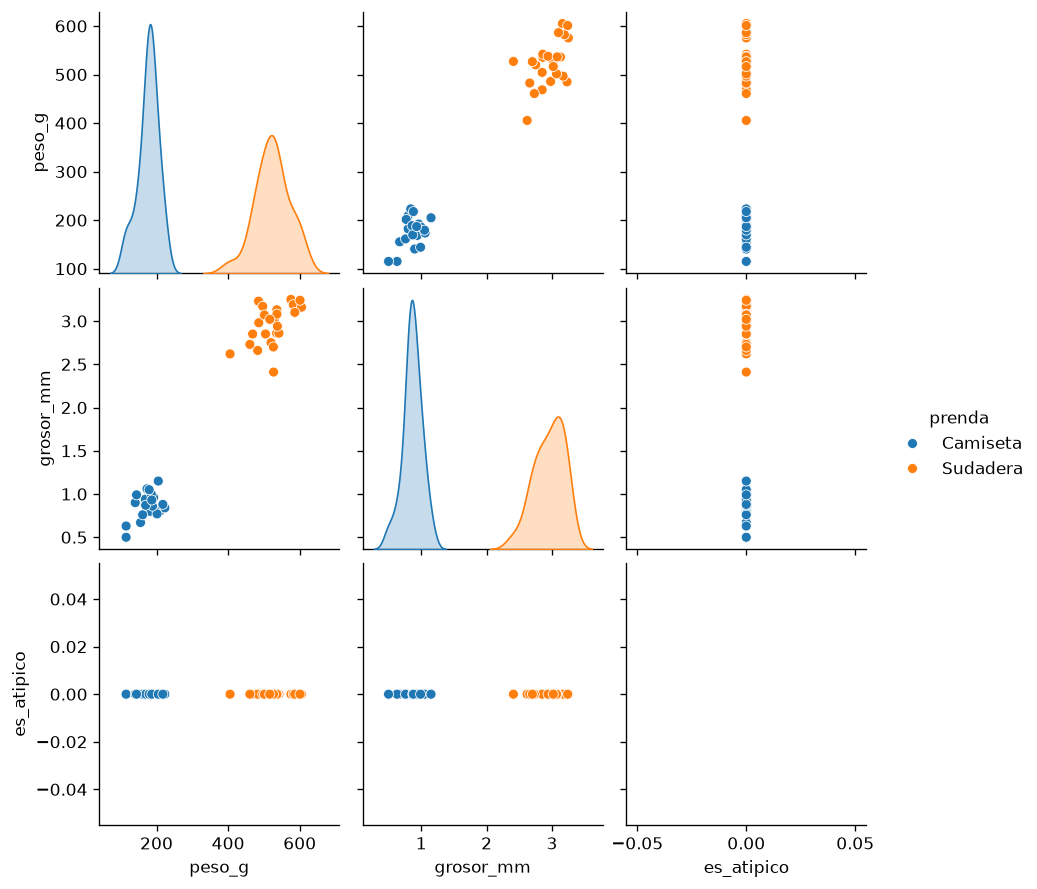

In [2]:
import seaborn as sns
df = datos[1]
sns.pairplot(df, hue = "prenda")

In [3]:
df[["peso_g", "grosor_mm"]].corr()

,peso_g,grosor_mm
peso_g,1.000000,0.980966
grosor_mm,0.980966,1.000000


## 2. Miremos los datos antes de entrenar

Cada punto es una prenda. El color es la etiqueta conocida. En el segundo gráfico, la estrella **C25** es una camiseta atípica: pesa y mide en grosor como una sudadera. Observa también que las nubes normales del caso 2 se mezclan.

**Pregunta para clase:** si llega una prenda de 330 g y 1,85 mm, ¿qué etiqueta le pondrías? ¿Con qué seguridad?


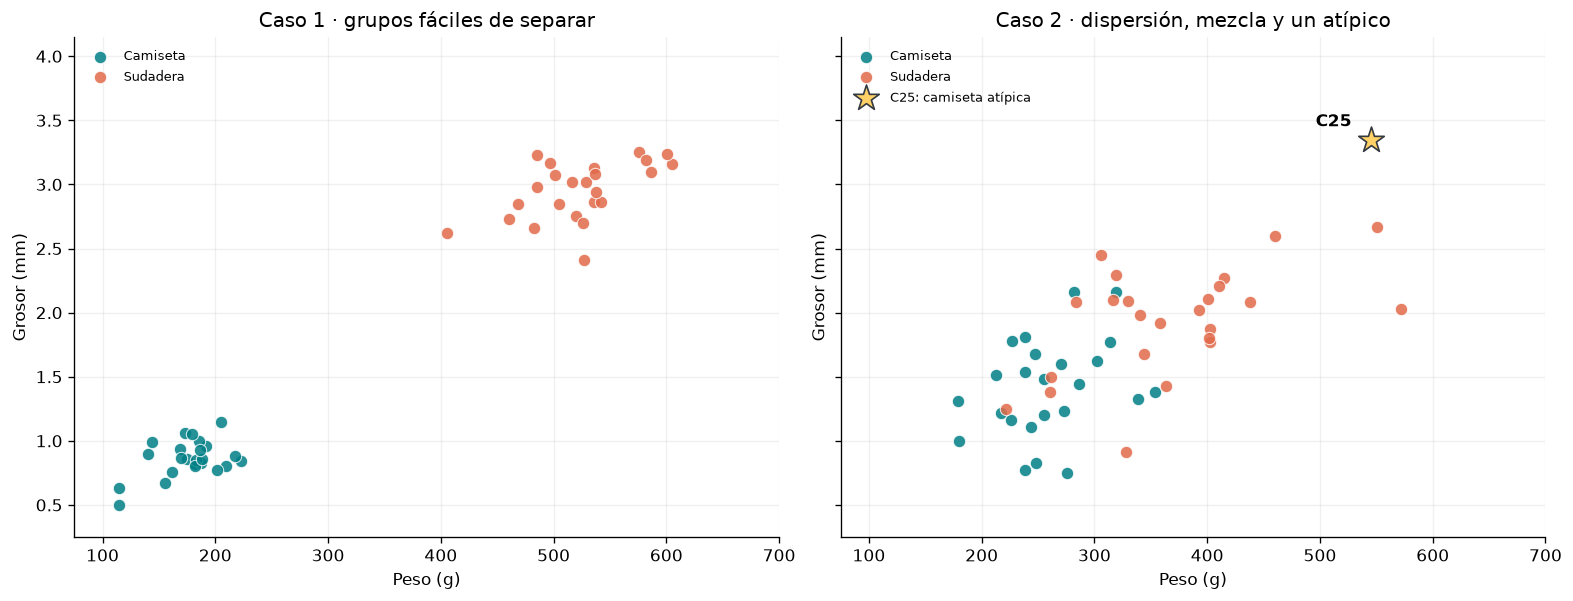

In [4]:
def dibujar_puntos(ax, tabla, titulo):
    for clase, color in COLORES.items():
        normales = tabla[(tabla["prenda"] == clase) & (tabla["es_atipico"] == 0)]
        ax.scatter(normales["peso_g"], normales["grosor_mm"],
                   s=55, c=color, edgecolors="white", linewidths=0.6,
                   alpha=0.85, label=clase, zorder=3)
    atipicos = tabla[tabla["es_atipico"] == 1]
    if not atipicos.empty:
        ax.scatter(atipicos["peso_g"], atipicos["grosor_mm"],
                   marker="*", s=260, c="#FFD166", edgecolors="#343A40",
                   linewidths=1, label="C25: camiseta atípica", zorder=5)
        fila = atipicos.iloc[0]
        ax.annotate("C25", (fila["peso_g"], fila["grosor_mm"]),
                    xytext=(-33, 8), textcoords="offset points", fontweight="bold")
    ax.set(xlim=(75, 700), ylim=(0.25, 4.15), xlabel="Peso (g)",
           ylabel="Grosor (mm)", title=titulo)
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, loc="upper left", fontsize=8)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.9), sharex=True, sharey=True,
                         constrained_layout=True)
dibujar_puntos(ejes[0], datos[1], "Caso 1 · grupos fáciles de separar")
dibujar_puntos(ejes[1], datos[2], "Caso 2 · dispersión, mezcla y un atípico")
plt.show()


In [5]:
# La distancia entre promedios ayuda, pero también importa cuánto se dispersa cada grupo.
for caso, tabla in datos.items():
    resumen = tabla.groupby("prenda")[VARIABLES].agg(["mean", "std"]).round(2)
    print(f"CASO {caso} · media y desviación típica")
    display(resumen)


CASO 1 · media y desviación típica


peso_g        grosor_mm      
            mean    std      mean   std
prenda                                 
Camiseta  176.68  27.87      0.86  0.14
Sudadera  522.74  47.03      2.95  0.23

CASO 2 · media y desviación típica


peso_g        grosor_mm      
            mean    std      mean   std
prenda                                 
Camiseta  270.68  72.09      1.49  0.54
Sudadera  369.82  83.97      1.94  0.42

## 3. Qué aprende LDA

**LDA = análisis discriminante lineal.** Usa las etiquetas conocidas para buscar una separación entre clases teniendo en cuenta sus centros y su dispersión. En este ejemplo, cada prenda tiene dos coordenadas: peso y grosor.

El clasificador aprende una **frontera recta**. A un lado predice `Camiseta`; al otro, `Sudadera`. También estima probabilidades mediante un modelo estadístico que supone, entre otras cosas, distribuciones aproximadamente gaussianas y una dispersión compartida entre clases.

Usamos exactamente las mismas dos variables en ambos casos para que la diferencia la pongan los datos, no el código. La columna `es_atipico` sirve únicamente para resaltar el punto en las gráficas.


In [6]:
modelos = {}
for caso, tabla in datos.items():
    modelo = LinearDiscriminantAnalysis()
    modelo.fit(tabla[VARIABLES], tabla["prenda"])
    modelos[caso] = modelo
    print(f"Caso {caso}: clases aprendidas = {list(modelo.classes_)}")


Caso 1: clases aprendidas = [np.str_('Camiseta'), np.str_('Sudadera')]
Caso 2: clases aprendidas = [np.str_('Camiseta'), np.str_('Sudadera')]


## 4. Calcular la dirección discriminante

LDA busca una **dirección** en la que los centros de las clases queden lejos y los puntos de cada clase queden lo más juntos posible. Con dos variables, esa dirección es una flecha. La **frontera de decisión** forma un ángulo recto con la flecha.

Primero estandarizamos peso y grosor para dibujarlos en una escala comparable: un paso en cada eje equivale a **una desviación típica** de esa medida. Esto cambia las unidades del gráfico, pero conserva la clasificación. Calculamos:

$$\mathbf{w}=S_W^{-1}(\boldsymbol{\mu}_{\mathrm{Sudadera}}-\boldsymbol{\mu}_{\mathrm{Camiseta}}),\qquad \mathbf{u}=\frac{\mathbf{w}}{\lVert\mathbf{w}\rVert}$$

Aquí, $\boldsymbol{\mu}$ son los centros de cada grupo; $S_W$ resume su dispersión **dentro** de las clases; y $\mathbf{u}$ es la flecha de longitud 1, orientada hacia `Sudadera`. El **corte** queda en el punto de esa dirección donde el modelo estima 50 % para cada clase. Veremos también que el corte puede desplazarse si las clases tienen distinta frecuencia.


In [7]:
from sklearn.preprocessing import StandardScaler

direcciones = {}
filas_resumen = []

for caso, tabla in datos.items():
    X = tabla[VARIABLES].to_numpy()
    y = tabla["prenda"].to_numpy()
    escala = StandardScaler().fit(X)
    Z = escala.transform(X)
    camisetas = Z[y == "Camiseta"]
    sudaderas = Z[y == "Sudadera"]
    mu_c = camisetas.mean(axis=0)
    mu_s = sudaderas.mean(axis=0)

    # Una matriz de dispersión compartida, calculada con ambas clases.
    S_c = np.cov(camisetas, rowvar=False, bias=True)
    S_s = np.cov(sudaderas, rowvar=False, bias=True)
    S_W = (len(camisetas) * S_c + len(sudaderas) * S_s) / len(Z)

    w = np.linalg.solve(S_W, mu_s - mu_c)
    u = w / np.linalg.norm(w)

    # El intercepto aprendido por LDA permite ubicar el corte exacto del 50 %.
    modelo_z = LinearDiscriminantAnalysis().fit(Z, y)
    if np.dot(u, modelo_z.coef_[0]) < 0:
        u = -u
    corte = -modelo_z.intercept_[0] / np.dot(modelo_z.coef_[0], u)
    assert np.array_equal(modelo_z.predict(Z), modelos[caso].predict(X))

    direcciones[caso] = {"Z": Z, "u": u, "corte": corte,
                         "escala": escala, "mu_c": mu_c, "mu_s": mu_s}
    filas_resumen.append({
        "Caso": caso,
        "Dirección · peso": u[0],
        "Dirección · grosor": u[1],
        "Centro camiseta": mu_c @ u,
        "Corte 50 %": corte,
        "Centro sudadera": mu_s @ u,
    })

display(pd.DataFrame(filas_resumen).set_index("Caso").round(2))
print("Los coeficientes indican cuánto aporta cada medida en la escala estandarizada.")


/opt/conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearDiscriminantAnalysis was fitted with feature names
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearDiscriminantAnalysis was fitted with feature names
  warnings.warn(


,Dirección · peso,Dirección · grosor,Centro camiseta,Corte 50 %,Centro sudadera
Caso,,,,,
1,0.38,0.92,-1.28,-0.00,1.28
2,0.98,0.20,-0.61,0.04,0.63


Los coeficientes indican cuánto aporta cada medida en la escala estandarizada.


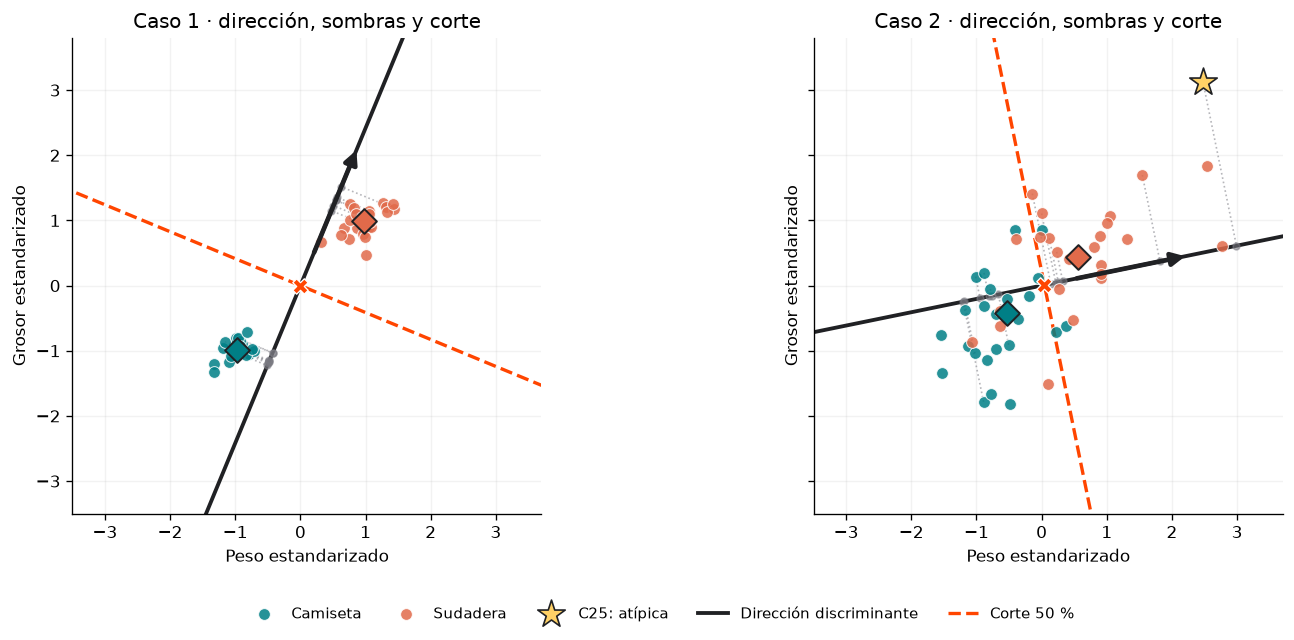

In [8]:
# Negro: dirección que hemos calculado. Naranja discontinua: corte del 50 %.
# Los segmentos grises muestran la "sombra" de algunas prendas sobre la dirección.
fig, ejes = plt.subplots(1, 2, figsize=(13, 5.4), sharex=True, sharey=True)
tramo = np.array([-4.6, 4.6])

for caso, ax in zip((1, 2), ejes):
    info = direcciones[caso]
    Z, u, corte = info["Z"], info["u"], info["corte"]
    tabla = datos[caso]

    # Proyectamos solo una muestra de puntos para mantener el gráfico legible.
    indices = np.linspace(0, len(Z) - 1, 13, dtype=int)
    for i in indices:
        sombra = (Z[i] @ u) * u
        ax.plot([Z[i, 0], sombra[0]], [Z[i, 1], sombra[1]],
                color="#7A7A82", linestyle=":", linewidth=1, alpha=0.55)
        ax.scatter(*sombra, s=16, color="#7A7A82", alpha=0.55, zorder=3)

    for clase, color in COLORES.items():
        mascara = (tabla["prenda"] == clase) & (tabla["es_atipico"] == 0)
        ax.scatter(Z[mascara, 0], Z[mascara, 1], s=50, c=color,
                   edgecolors="white", linewidths=0.6, alpha=0.85,
                   label=clase, zorder=4)
        centro = info["mu_c"] if clase == "Camiseta" else info["mu_s"]
        ax.scatter(*centro, marker="D", s=110, c=color,
                   edgecolors="#202124", linewidths=1.2, zorder=6)

    if caso == 2:
        atipico = tabla["es_atipico"].to_numpy() == 1
        ax.scatter(Z[atipico, 0], Z[atipico, 1], marker="*", s=300,
                   c="#FFD166", edgecolors="#202124", linewidths=1,
                   label="C25: atípica", zorder=7)

    ax.plot(tramo * u[0], tramo * u[1], color="#202124",
            linewidth=2.3, label="Dirección discriminante", zorder=2)
    ax.annotate("", xy=2.3 * u, xytext=0.5 * u,
                arrowprops={"arrowstyle": "-|>", "color": "#202124",
                            "lw": 2.8, "mutation_scale": 16}, zorder=8)

    perpendicular = np.array([-u[1], u[0]])
    punto_corte = corte * u
    frontera = punto_corte + tramo[:, None] * perpendicular
    ax.plot(frontera[:, 0], frontera[:, 1], "--", color="#FF4500",
            linewidth=2, label="Corte 50 %", zorder=2)
    ax.scatter(*punto_corte, s=85, c="#FF4500", marker="X",
               edgecolors="white", linewidths=0.8, zorder=8)
    ax.set(xlim=(-3.5, 3.7), ylim=(-3.5, 3.8),
           xlabel="Peso estandarizado", ylabel="Grosor estandarizado",
           title=f"Caso {caso} · dirección, sombras y corte")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.16)

handles, labels = ejes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False,
           bbox_to_anchor=(0.5, 0.01), fontsize=9)
fig.tight_layout(rect=(0, 0.09, 1, 1))
plt.show()


## 5. Ver la frontera y la zona de duda

El fondo representa la probabilidad **estimada** de `Sudadera`: azul claro equivale a valores bajos y naranja a valores altos. La línea negra marca el **50 %**: allí cambia la decisión. Las líneas discontinuas indican 20 % y 80 %.

En el caso 1, la frontera cae en un espacio sin prendas. En el caso 2 atraviesa una región poblada: las prendas próximas a ella son más difíciles de clasificar. Fíjate en C25, que queda entre sudaderas pese a su etiqueta real.


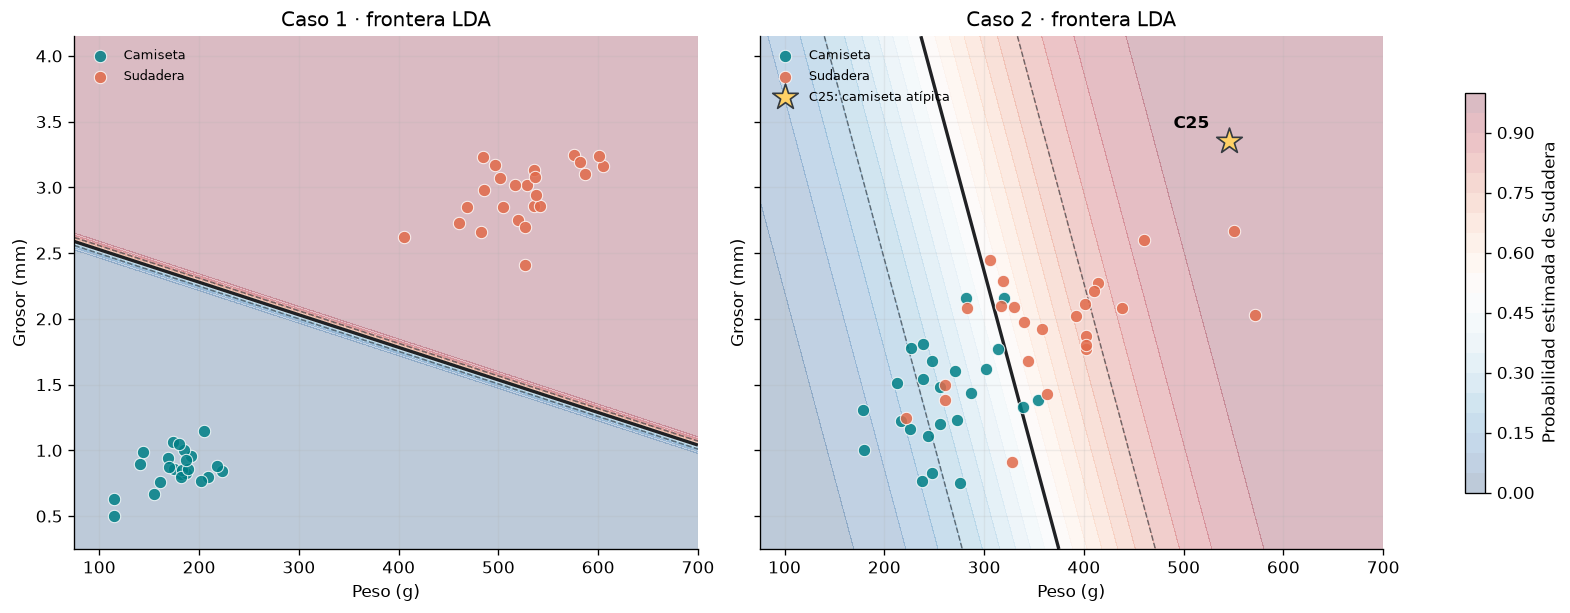

In [9]:
xx, yy = np.meshgrid(np.linspace(75, 700, 300),
                     np.linspace(0.25, 4.15, 250))
rejilla = pd.DataFrame({"peso_g": xx.ravel(), "grosor_mm": yy.ravel()})

fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True,
                         constrained_layout=True)
for caso, ax in zip((1, 2), ejes):
    modelo = modelos[caso]
    indice_sudadera = list(modelo.classes_).index("Sudadera")
    p = modelo.predict_proba(rejilla)[:, indice_sudadera].reshape(xx.shape)
    fondo = ax.contourf(xx, yy, p, levels=np.linspace(0, 1, 21),
                        cmap="RdBu_r", alpha=0.27, vmin=0, vmax=1)
    ax.contour(xx, yy, p, levels=[0.2, 0.8], colors="#343A40",
               linestyles="--", linewidths=0.9, alpha=0.65)
    ax.contour(xx, yy, p, levels=[0.5], colors="#202124", linewidths=2)
    dibujar_puntos(ax, datos[caso], f"Caso {caso} · frontera LDA")
fig.colorbar(fondo, ax=ejes, shrink=0.78,
             label="Probabilidad estimada de Sudadera")
plt.show()


## 6. La misma información proyectada en un solo eje

Ahora vemos únicamente las **sombras** sobre la dirección calculada. La línea discontinua es el mismo corte del 50 % del gráfico anterior. En el caso sencillo aparecen dos montones separados; en el difícil se pisan. Es la misma decisión vista en una sola dimensión.


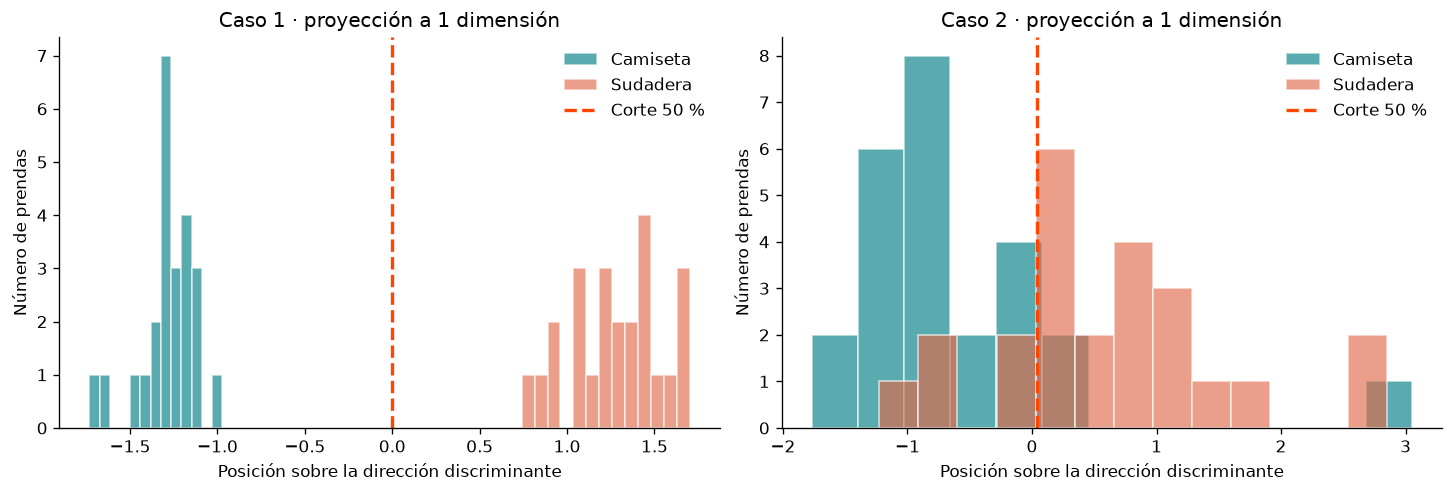

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for caso, ax in zip((1, 2), ejes):
    tabla = datos[caso]
    info = direcciones[caso]
    proyeccion = info["Z"] @ info["u"]
    for clase, color in COLORES.items():
        valores = proyeccion[tabla["prenda"].to_numpy() == clase]
        ax.hist(valores, bins=13, alpha=0.65, color=color, edgecolor="white",
                label=clase)
    ax.axvline(info["corte"], color="#FF4500", linestyle="--",
               linewidth=2, label="Corte 50 %")
    ax.set(xlabel="Posición sobre la dirección discriminante",
           ylabel="Número de prendas",
           title=f"Caso {caso} · proyección a 1 dimensión")
    ax.legend(frameon=False)
plt.show()


## 7. Una prenda nueva: decisión y porcentaje

Supongamos que llega una prenda **sin etiqueta** de 330 g y 1,85 mm. El modelo del **caso 2** recibe únicamente sus medidas. Cambia esos números y vuelve a ejecutar las dos celdas siguientes para probar otros ejemplos.

- `predict` devuelve la **decisión**: la clase con mayor probabilidad estimada.
- `predict_proba` devuelve una probabilidad para **cada** clase. Su suma es 100 %.

No interpretamos el porcentaje como «el 73 % de la prenda es una sudadera». La prenda tendrá una clase real; el porcentaje expresa la **incertidumbre del modelo**, dadas sus suposiciones y estos datos de entrenamiento. Como regla docente, si ninguna clase alcanza el 80 %, mandaremos la prenda a revisión humana; ese umbral habría que validarlo con datos reales.


In [11]:
# EDITA ESTAS DOS CIFRAS Y VUELVE A EJECUTAR.
nueva = pd.DataFrame({"peso_g": [330.0], "grosor_mm": [1.85]})
modelo = modelos[2]
decision = modelo.predict(nueva)[0]
probabilidades = modelo.predict_proba(nueva)[0]
accion = ("Clasificar automáticamente" if probabilidades.max() >= 0.80
          else "Revisión humana")

resultado = pd.DataFrame({
    "Prenda": [f"{nueva.at[0, 'peso_g']:.0f} g · {nueva.at[0, 'grosor_mm']:.2f} mm"],
    "Decisión": [decision],
    **{f"P({clase})": [f"{100 * p:.1f} %"]
       for clase, p in zip(modelo.classes_, probabilidades)},
    "Acción": [accion],
})
display(resultado)
print(f"Comprobación: las probabilidades suman {probabilidades.sum() * 100:.1f} %")


,Prenda,Decisión,P(Camiseta),P(Sudadera),Acción
0,330 g · 1.85 mm,Sudadera,45.8 %,54.2 %,Revisión humana


Comprobación: las probabilidades suman 100.0 %


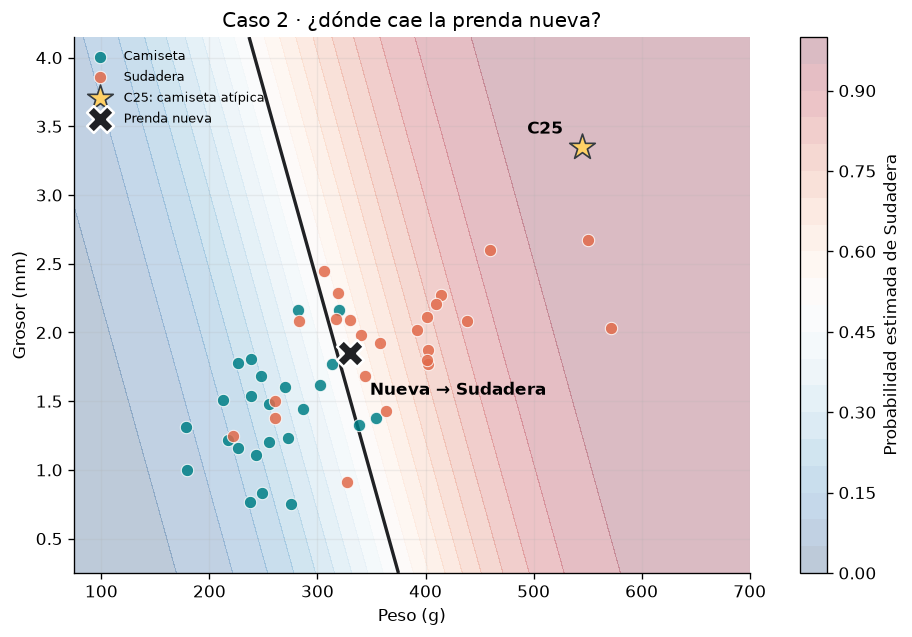

In [12]:
# El mismo punto, situado sobre el mapa de probabilidades.
p_sudadera = modelo.predict_proba(rejilla)[:, list(modelo.classes_).index("Sudadera")]
p_sudadera = p_sudadera.reshape(xx.shape)
fig, ax = plt.subplots(figsize=(7.5, 5.2), constrained_layout=True)
fondo = ax.contourf(xx, yy, p_sudadera, levels=np.linspace(0, 1, 21),
                    cmap="RdBu_r", alpha=0.27, vmin=0, vmax=1)
ax.contour(xx, yy, p_sudadera, levels=[0.5], colors="#202124", linewidths=2)
dibujar_puntos(ax, datos[2], "Caso 2 · ¿dónde cae la prenda nueva?")
ax.scatter(nueva["peso_g"], nueva["grosor_mm"], marker="X", s=260,
           c="#202124", edgecolors="white", linewidths=1.5,
           label="Prenda nueva", zorder=7)
ax.annotate(f"Nueva → {decision}", (nueva.at[0, 'peso_g'], nueva.at[0, 'grosor_mm']),
            xytext=(12, -25), textcoords="offset points", fontweight="bold")
ax.legend(frameon=False, loc="upper left", fontsize=8)
fig.colorbar(fondo, ax=ax, label="Probabilidad estimada de Sudadera")
plt.show()


## 8. ¿Qué cambia por la camiseta atípica?

Comparamos el modelo entrenado con todas las prendas frente a otro entrenado **sin C25**. El dato atípico puede mover la frontera porque influye en el centro y la dispersión de la clase `Camiseta`. El gráfico permite observar cuánto cambia la probabilidad asignada a una misma prenda nueva.

**Importante:** no borres un dato real solo porque sea incómodo. Primero comprueba si es un error de medida, una prenda de otro tipo o un caso verdadero que también debe poder reconocer el sistema.


Con C25: P(Sudadera | prenda nueva) = 54.2 %
Sin C25: P(Sudadera | prenda nueva) = 65.1 %


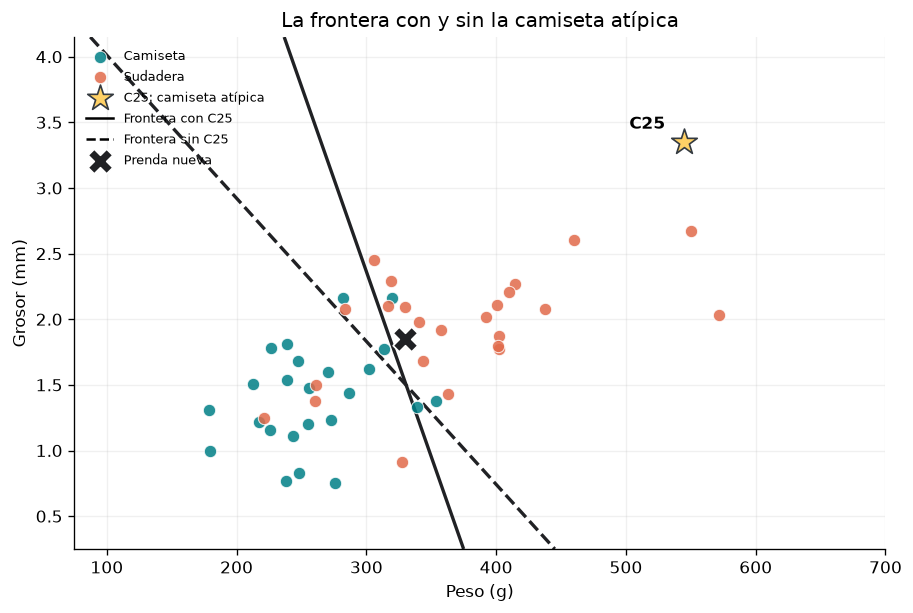

In [13]:
sin_atipico = datos[2].query("es_atipico == 0")
modelo_sin = LinearDiscriminantAnalysis().fit(
    sin_atipico[VARIABLES], sin_atipico["prenda"]
)

fig, ax = plt.subplots(figsize=(7.5, 5), constrained_layout=True)
for nombre, m, estilo in [
    ("Con C25", modelos[2], "-"),
    ("Sin C25", modelo_sin, "--"),
]:
    indice = list(m.classes_).index("Sudadera")
    p = m.predict_proba(rejilla)[:, indice].reshape(xx.shape)
    ax.contour(xx, yy, p, levels=[0.5], colors="#202124",
               linestyles=estilo, linewidths=2)
    print(f"{nombre}: P(Sudadera | prenda nueva) = "
          f"{m.predict_proba(nueva)[0, indice] * 100:.1f} %")

dibujar_puntos(ax, datos[2], "La frontera con y sin la camiseta atípica")
ax.plot([], [], "k-", label="Frontera con C25")
ax.plot([], [], "k--", label="Frontera sin C25")
ax.scatter(nueva["peso_g"], nueva["grosor_mm"], marker="X", s=220,
           c="#202124", edgecolors="white", label="Prenda nueva", zorder=7)
ax.legend(frameon=False, loc="upper left", fontsize=8)
plt.show()


## 9. Una comprobación modesta de generalización

Acertar en las prendas que se usaron para ajustar el modelo sería una medida demasiado optimista. Hacemos una **validación cruzada estratificada de 5 partes**: en cada ronda se entrena con cuatro partes y se evalúa con la quinta. Compara los dos casos, pero recuerda que estos CSV son pequeños y sintéticos.


In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for caso, tabla in datos.items():
    aciertos = cross_val_score(LinearDiscriminantAnalysis(),
                              tabla[VARIABLES], tabla["prenda"],
                              cv=cv, scoring="accuracy")
    print(f"Caso {caso}: exactitud media = {aciertos.mean():.1%} "
          f"| pliegues: {[f'{valor:.0%}' for valor in aciertos]}")


Caso 1: exactitud media = 100.0% | pliegues: ['100%', '100%', '100%', '100%', '100%']
Caso 2: exactitud media = 83.6% | pliegues: ['90%', '80%', '80%', '90%', '78%']


## Para comentar en clase

1. ¿Por qué en el caso 1 podemos tener mucha más seguridad visual que en el 2?
2. ¿Qué diferencia hay entre **etiqueta predicha** y **probabilidad estimada**?
3. ¿Qué harías con una prenda próxima a la línea del 50 %? Una opción práctica es pedir revisión humana si la probabilidad mayor es inferior al 80 %.
4. ¿Qué información adicional pedirías antes de usar esto en una tienda real?

**Límite importante:** las probabilidades dependen de los datos y de los supuestos de LDA. Con solapamiento, valores atípicos o cambios en el catálogo, pueden estar mal calibradas. Para una aplicación real habría que reunir datos representativos, separar un conjunto de prueba y comprobar la calibración de las probabilidades.

**Referencia de la herramienta:** [guía oficial de LDA de scikit-learn](https://scikit-learn.org/stable/modules/lda_qda.html) y [API de `LinearDiscriminantAnalysis`](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html).
